Unsupervised Learning

In [1]:
import pandas as pd 
import numpy as np

In [2]:
df = pd.read_csv("../data/churn_cleaned.csv")
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,BalanceCategory,TenureGroup
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,41-50,Zero,New (0-2 yrs)
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,41-50,High,New (0-2 yrs)
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,41-50,Very High,Long (6-10 yrs)
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,31-40,Zero,New (0-2 yrs)
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,41-50,Very High,New (0-2 yrs)


In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = df[['Age', 'Balance', 'EstimatedSalary', 'Tenure', 'NumOfProducts']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_scaled)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[[ 0.

In [5]:
clusters = kmeans.labels_

In [6]:
df['Cluster'] = clusters

In [7]:
cluster_profiles = df.groupby('Cluster')[['Age', 'Balance', 'EstimatedSalary', 'Tenure', 'NumOfProducts']].mean()

print(cluster_profiles)

               Age        Balance  EstimatedSalary    Tenure  NumOfProducts
Cluster                                                                    
0        39.897269  113152.889410    105295.838898  7.593731       1.267846
1        38.858059  109483.724493     96109.815632  2.333639       1.279609
2        38.083952   11882.239223     99024.400306  5.144489       2.005997


In [8]:
pd.crosstab(
    df["Cluster"],
    df["Geography"],
    normalize="index"
)

Geography,France,Germany,Spain
Cluster,,,
0,0.429547,0.354128,0.216325
1,0.438950,0.347375,0.213675
2,0.625928,0.065677,0.308395


In [9]:
pd.crosstab(
    df["Cluster"],
    df["IsActiveMember"],
    normalize="index"
)

IsActiveMember,0,1
Cluster,,
0,0.502173,0.497827
1,0.466422,0.533578
2,0.486294,0.513706


Now Well define the Value of K

For each K:

K = 2
K = 3
K = 4
K = 5
K = 6
...

we train K-Means and measure how tightly the points are grouped.

The measurement K-Means gives us is:

kmeans.inertia_

How much total distance exists between observations and the centroid of their assigned cluster.


In [10]:
inertia = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

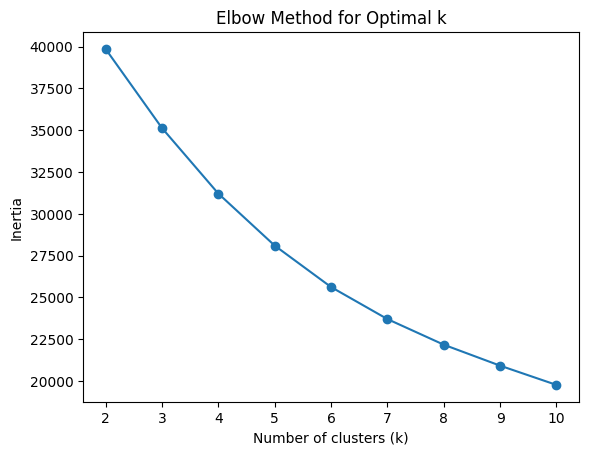

In [11]:
import matplotlib.pyplot as plt

plt.plot(range(2,11), inertia, marker='o')

plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.show()

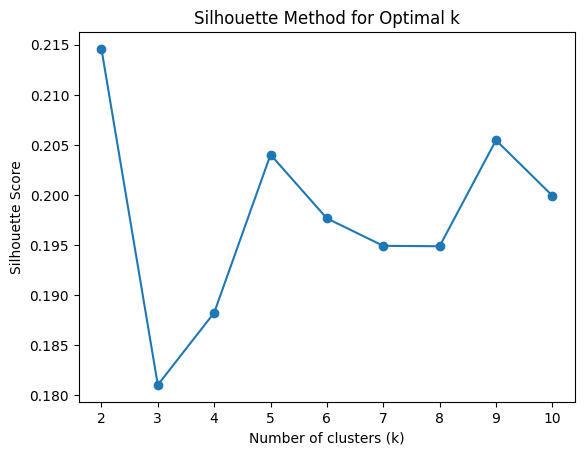

In [12]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

plt.plot(range(2,11), silhouette_scores, marker='o')
plt.title('Silhouette Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()

We got a peak at k=5 (kyuki k=2 par sil vala test mjorly peak deta hi hai isliye elbow point aur dusre eval ka use bhi karna chahiye)

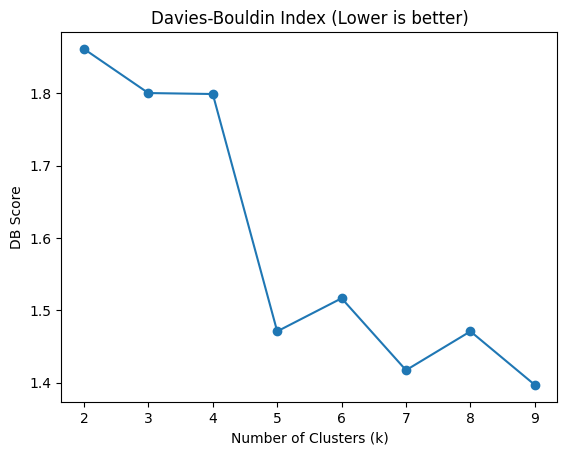

In [13]:
from sklearn.metrics import davies_bouldin_score

db_scores = []
for k in range(2, 10):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X_scaled)
    db_scores.append(davies_bouldin_score(X_scaled, labels))

# Iska plot banao aur minimum point dekho
plt.plot(range(2, 10), db_scores, marker='o')
plt.title('Davies-Bouldin Index (Lower is better)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('DB Score')
plt.show()

In [14]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters

In [15]:
df['Cluster'].value_counts()

Cluster
0    2804
2    2107
1    2024
4    1972
3    1093
Name: count, dtype: int64

In [16]:
cluster_profile = df.groupby("Cluster")[
    [
        "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "Tenure",
        "NumOfProducts"
    ]
].mean()

print(cluster_profile)

               Age        Balance  EstimatedSalary  CreditScore    Tenure  \
Cluster                                                                     
0        35.514979    1054.226041     98901.410606   649.796362  5.148003   
1        36.293972  105236.848715     96937.434995   648.347826  2.266304   
2        36.860465  108731.160693    104622.555596   651.074039  7.565733   
3        60.242452   72227.505691     94189.821757   650.485819  4.860933   
4        36.848377  122141.096329    103444.358631   653.250000  4.995943   

         NumOfProducts  
Cluster                 
0             1.959344  
1             1.000988  
2             1.000000  
3             1.354071  
4             2.127282  


Profile the clusters visually

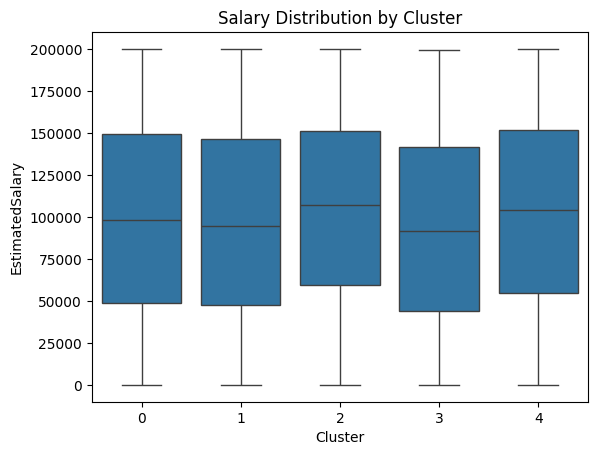

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df,
    x="Cluster",
    y="EstimatedSalary"
)

plt.title("Salary Distribution by Cluster")
plt.show()

① Cluster sizes

In [18]:
df["Cluster"].value_counts()

Cluster
0    2804
2    2107
1    2024
4    1972
3    1093
Name: count, dtype: int64

② Numerical profile

In [19]:
df.groupby("Cluster")[
    [
        "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "Tenure",
        "NumOfProducts"
    ]
].mean()

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
Cluster,,,,,,
0,35.514979,1054.226041,98901.410606,649.796362,5.148003,1.959344
1,36.293972,105236.848715,96937.434995,648.347826,2.266304,1.000988
2,36.860465,108731.160693,104622.555596,651.074039,7.565733,1.000000
3,60.242452,72227.505691,94189.821757,650.485819,4.860933,1.354071
4,36.848377,122141.096329,103444.358631,653.250000,4.995943,2.127282


③ Churn profile

In [20]:
df.groupby("Cluster")["Exited"].mean()

Cluster
0    0.074536
1    0.235178
2    0.236355
3    0.420860
4    0.199797
Name: Exited, dtype: float64

Visualisation of Clusters

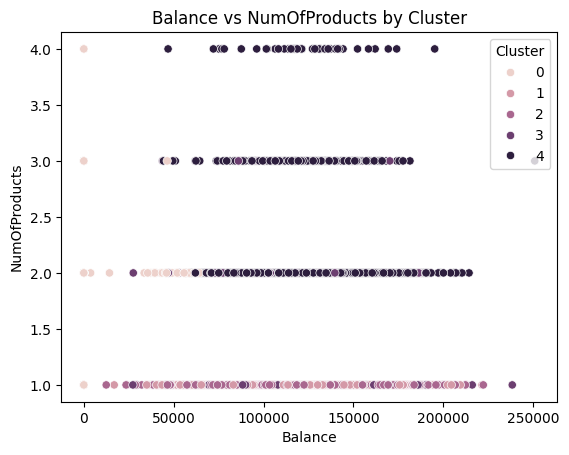

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x="Balance",
    y="NumOfProducts",
    hue="Cluster"
)

plt.title("Balance vs NumOfProducts by Cluster")
plt.show()

**PCA — Principal Component Analysis**

The core idea

Imagine your data looks like this:

       ●
     ●
   ●
 ●
●

The data has much more variation along the diagonal than vertically.

PCA finds that direction.

That becomes:

PC1 — Principal Component 1

Then it finds another direction perpendicular to PC1:

PC2 — Principal Component 2

So:

Original space

Age
Balance
Salary
CreditScore
Tenure
Products
      ↓
     PCA
      ↓
PC1
PC2

These aren't original columns.

They're new combinations of the original columns.

In [22]:
# It starts with Standard Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [23]:
# Now we are gonna reduce the dimensionality of our data using PCA (Principal Component Analysis) to visualize the clusters in 2D space.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [24]:
X_pca.shape

(10000, 2)

In [25]:
pca.components_  # this provide loading coefficients for each feature in the principal components
# That means we can see how much each feature contributes to the principal components. 
# The first row corresponds to the first principal component, and the second row corresponds to the second principal component.
# The values indicate the weight of each feature in the respective principal component.

array([[-0.13480886, -0.69874991,  0.00788598,  0.0623067 ,  0.69973625],
       [-0.46682624,  0.1053982 ,  0.65014422,  0.58847628, -0.04441441]])

In [26]:
print(pca.explained_variance_ratio_) # this provide the amount of variance explained by each principal component

[0.26220377 0.20266408]


In [27]:
pca.explained_variance_ratio_.sum()

np.float64(0.4648678532734724)

Since the PCA variance ratio is 46 percent which means that it describes only 46 percent of the total dataset so we are gonna use it only for visualisation and the model training of k means 

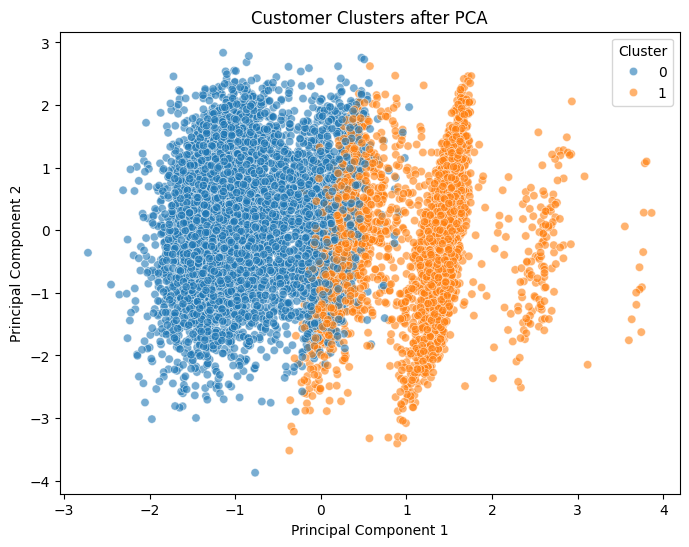

In [28]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df["Cluster"],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Clusters after PCA")

plt.show()

Let's inspect the PCA loadings

In [29]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

loadings

,PC1,PC2
Age,-0.134809,-0.466826
Balance,-0.698750,0.105398
EstimatedSalary,0.007886,0.650144
Tenure,0.062307,0.588476
NumOfProducts,0.699736,-0.044414


Heirarchial Clusters

In [30]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward')

df['HC_Cluster'] = hc.fit_predict(X_scaled)

df['HC_Cluster'].value_counts()

HC_Cluster
0    5362
1    4638
Name: count, dtype: int64

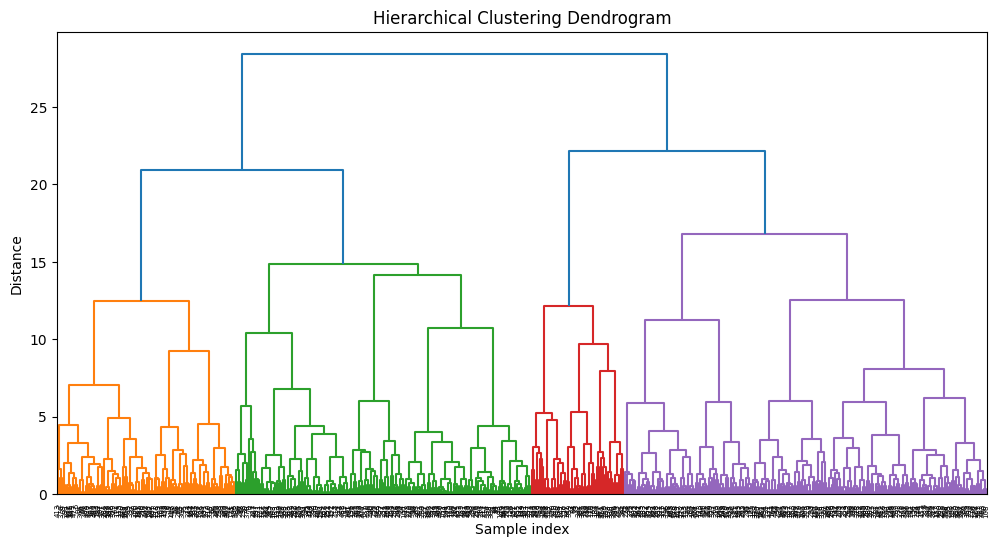

In [31]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

sample = X_scaled[:500]  # taking a sample of 500 for better visualization
Z = linkage(sample, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample index")
plt.ylabel("Distance")
plt.show()


In [32]:
cluster_profile = df.groupby("HC_Cluster")[
    [
        "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "Tenure",
        "NumOfProducts"
    ]
].mean()

cluster_profile

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
HC_Cluster,,,,,,
0,36.569937,45887.381186,100950.418420,650.045132,5.024618,1.918874
1,41.640793,111860.878603,99095.785951,651.087969,4.999138,1.080854


In [33]:
cluster_profile.T

HC_Cluster,0,1
Age,36.569937,41.640793
Balance,45887.381186,111860.878603
EstimatedSalary,100950.418420,99095.785951
CreditScore,650.045132,651.087969
Tenure,5.024618,4.999138
NumOfProducts,1.918874,1.080854


Till now we have focused on building cluster Now we are gonna go for post cluster profiling

In [34]:
df.groupby("HC_Cluster")['Exited'].mean()  

HC_Cluster
0    0.157031
1    0.257654
Name: Exited, dtype: float64

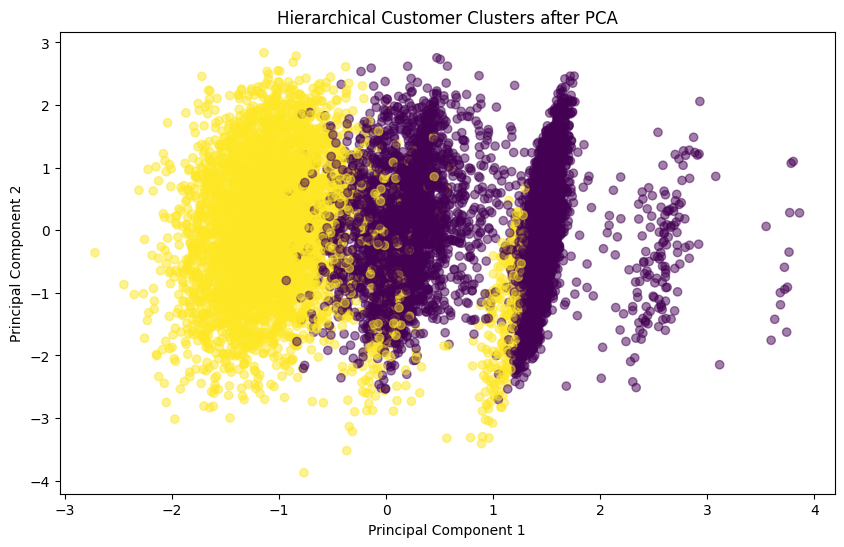

In [35]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["HC_Cluster"],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Customer Clusters after PCA")

plt.show()

In [36]:
df["HC_Cluster"].value_counts()

HC_Cluster
0    5362
1    4638
Name: count, dtype: int64

In [37]:
df.groupby("HC_Cluster")[
    ["Age", "Balance", "EstimatedSalary",
     "CreditScore", "Tenure", "NumOfProducts"]
].mean()

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
HC_Cluster,,,,,,
0,36.569937,45887.381186,100950.418420,650.045132,5.024618,1.918874
1,41.640793,111860.878603,99095.785951,651.087969,4.999138,1.080854


In [38]:
df.groupby("HC_Cluster")["Exited"].mean()

HC_Cluster
0    0.157031
1    0.257654
Name: Exited, dtype: float64

In [39]:
pd.crosstab(
    df["Cluster"],
    df["HC_Cluster"]
)

HC_Cluster,0,1
Cluster,,
0,1526,4274
1,3836,364


DBSCAN Model

In [40]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8 , min_samples=5)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

In [41]:
df['DBSCAN_Cluster'].value_counts()

DBSCAN_Cluster
 0    5061
 1    4559
-1     174
 3     117
 2      77
 5       6
 4       6
Name: count, dtype: int64

In [42]:
df[df['DBSCAN_Cluster'] == -1][
    [ "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "Tenure",
        "NumOfProducts"]
        ].describe()

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000
mean,54.321839,85453.756897,102256.951609,642.718391,5.362069,2.867816
std,17.035152,64786.455579,63581.831485,89.663249,3.162451,1.002770
min,21.000000,0.000000,4733.940000,376.000000,0.000000,1.000000
25%,41.000000,0.000000,42085.527500,592.250000,3.000000,2.000000
50%,55.000000,96181.560000,104556.000000,643.000000,5.000000,3.000000
75%,69.750000,130780.475000,160331.205000,698.000000,8.750000,4.000000
max,92.000000,250898.090000,199357.240000,850.000000,10.000000,4.000000


In [43]:
df[[ "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "Tenure",
        "NumOfProducts"]].describe()

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,38.921800,76485.889288,100090.239881,650.528800,5.012800,1.530200
std,10.487806,62397.405202,57510.492818,96.653299,2.892174,0.581654
min,18.000000,0.000000,11.580000,350.000000,0.000000,1.000000
25%,32.000000,0.000000,51002.110000,584.000000,3.000000,1.000000
50%,37.000000,97198.540000,100193.915000,652.000000,5.000000,1.000000
75%,44.000000,127644.240000,149388.247500,718.000000,7.000000,2.000000
max,92.000000,250898.090000,199992.480000,850.000000,10.000000,4.000000


Now to get Reasonable Value for the eps we are gonna use the k nearest algorithm 

In [44]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

In [45]:
neighbors = NearestNeighbors(
    n_neighbors=5
)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

In [46]:
k_distances = distances[:, -1]

In [47]:
k_distances = np.sort(k_distances)

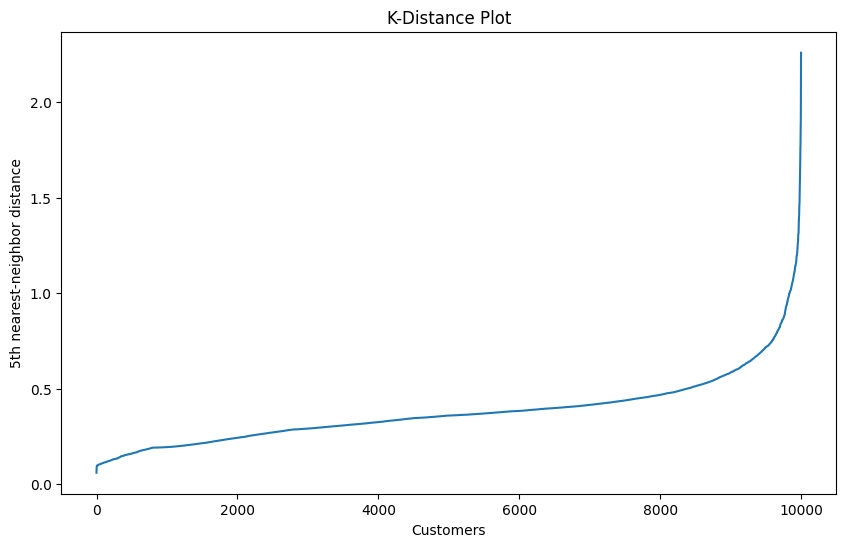

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(k_distances)

plt.xlabel("Customers")
plt.ylabel("5th nearest-neighbor distance")
plt.title("K-Distance Plot")

plt.show()

In [49]:
dbscan_075 = DBSCAN(eps=0.75 , min_samples=5)

labels_075 = dbscan_075.fit_predict(X_scaled)

pd.Series(labels_075).value_counts()

 0    5053
 1    4537
-1     235
 2      66
 3      54
 4      20
 5      15
 6       9
 7       6
 8       5
Name: count, dtype: int64

In [50]:
dbscan_07 = DBSCAN(eps=0.7 , min_samples=5)
labels_07 = dbscan_07.fit_predict(X_scaled)
pd.Series(labels_07).value_counts()

 0     5035
 1     4520
-1      300
 2       42
 3       24
 5       19
 4       13
 11      11
 6        9
 7        8
 10       7
 8        7
 9        5
Name: count, dtype: int64

In [51]:
df.groupby('DBSCAN_Cluster')[[
    "Age",
    "Balance",
    "EstimatedSalary",
    "CreditScore",
    "Tenure",
    "NumOfProducts"
]].mean()

,Age,Balance,EstimatedSalary,CreditScore,Tenure,NumOfProducts
DBSCAN_Cluster,,,,,,
-1,54.321839,85453.756897,102256.951609,642.718391,5.362069,2.867816
0,39.517289,98701.328018,99419.094347,649.192254,4.972733,1.000000
1,37.538495,51439.154036,100473.842395,652.306427,5.056372,2.000000
2,39.909091,1245.414935,104234.894416,654.142857,4.155844,3.000000
3,43.623932,121472.984530,106123.295641,647.068376,5.102564,3.000000
4,46.000000,124798.785000,135587.645000,751.666667,2.666667,4.000000
5,29.666667,149064.330000,105561.155000,573.666667,7.166667,3.000000


In [52]:
df.groupby('DBSCAN_Cluster')['Exited'].mean()   

DBSCAN_Cluster
-1    0.666667
 0    0.277613
 1    0.075455
 2    0.649351
 3    0.940171
 4    1.000000
 5    1.000000
Name: Exited, dtype: float64

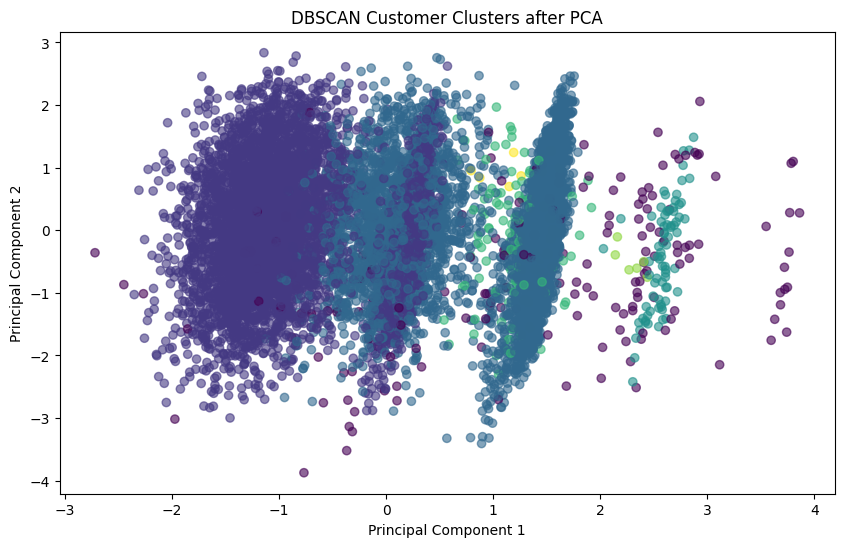

In [56]:
plt.figure(figsize=(10,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=df['DBSCAN_Cluster'],
    alpha=0.6
)

plt.title("DBSCAN Customer Clusters after PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()